# MicroCrack AI - Concrete Crack Detection


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os, time, json, random

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Environment ready!")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Environment ready!


## 1. Mount Drive and find the dataset
Dataset: *Concrete Crack Images for Classification* (Mendeley Data v2).

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
rar_path = "/content/drive/MyDrive/MicroCrack_Project/Concrete Crack Images for Classification.rar"   # <- change to your file

if os.path.exists(rar_path):
    size_mb = os.path.getsize(rar_path) / (1024 * 1024)
    print("✅ Dataset found!")
    print(f"File size: {size_mb:.2f} MB")
else:
    print("❌ Dataset not found. Check rar_path.")
    print("Files in MyDrive:", os.listdir("/content/drive/MyDrive"))

✅ Dataset found!
File size: 230.18 MB


## 2. Extract the dataset

## 3. Inspect the folder structure and count images
The dataset has only `Positive` (crack) and `Negative` (no crack) folders. There is **no official train/test split**, so we make one in Step 5.

In [6]:
extract_path = "/content/crack_dataset"
os.makedirs(extract_path, exist_ok=True)

!apt-get -qq install -y p7zip-full > /dev/null
!7z x "{rar_path}" -o"{extract_path}" -y > /dev/null

print("✅ Dataset extracted!")
for root, dirs, files in os.walk(extract_path):
    if root.count(os.sep) - extract_path.count(os.sep) <= 2:
        print(root, "| files:", len(files))

Streaming output truncated to the last 5000 lines.
ERROR: Unsupported Method : Negative/15005.jpg
ERROR: Unsupported Method : Negative/15006.jpg
ERROR: Unsupported Method : Negative/15007.jpg
ERROR: Unsupported Method : Negative/15008.jpg
ERROR: Unsupported Method : Negative/15009.jpg
ERROR: Unsupported Method : Negative/15010.jpg
ERROR: Unsupported Method : Negative/15011.jpg
ERROR: Unsupported Method : Negative/15012.jpg
ERROR: Unsupported Method : Negative/15013.jpg
ERROR: Unsupported Method : Negative/15014.jpg
ERROR: Unsupported Method : Negative/15015.jpg
ERROR: Unsupported Method : Negative/15016.jpg
ERROR: Unsupported Method : Negative/15017.jpg
ERROR: Unsupported Method : Negative/15018.jpg
ERROR: Unsupported Method : Negative/15019.jpg
ERROR: Unsupported Method : Negative/15020.jpg
ERROR: Unsupported Method : Negative/15021.jpg
ERROR: Unsupported Method : Negative/15022.jpg
ERROR: Unsupported Method : Negative/15023.jpg
ERROR: Unsupported Method : Negative/15024.jpg
ERROR: Un

In [10]:
import os, shutil
from PIL import Image

print(f"RAR size: {os.path.getsize(rar_path)/1e6:.1f} MB")   # should be tens/hundreds of MB, not 0

def check():
    ok = True
    for cls in ["Positive", "Negative"]:
        d = f"{extract_path}/{cls}"
        if not os.path.isdir(d):
            print(cls, "folder missing"); ok = False; continue
        files = sorted(os.listdir(d))
        zero = sum(os.path.getsize(f"{d}/{f}") == 0 for f in files)
        bad = 0
        for f in files[:200]:
            try: Image.open(f"{d}/{f}").verify()
            except Exception: bad += 1
        print(f"{cls}: {len(files)} files | 0-byte: {zero} | unreadable in first 200: {bad}")
        ok = ok and zero == 0 and bad == 0
    return ok

def fresh():
    shutil.rmtree(extract_path, ignore_errors=True)
    os.makedirs(extract_path, exist_ok=True)

# Attempt 1: unrar
fresh()
!apt-get -qq install -y unrar > /dev/null 2>&1
!unrar x -o+ -inul "{rar_path}" "{extract_path}/"
if not check():
    # Attempt 2: unar (handles RAR5)
    print("\nAttempt 1 failed, trying unar...")
    fresh()
    !apt-get -qq install -y unar > /dev/null 2>&1
    !unar -q -f -o "{extract_path}" "{rar_path}"
    check()

RAR size: 241.4 MB
Positive: 20000 files | 0-byte: 0 | unreadable in first 200: 0
Negative: 20000 files | 0-byte: 0 | unreadable in first 200: 0


In [11]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_dirs = {}
for root, dirs, files in os.walk(extract_path):
    if os.path.basename(root).lower() in ("positive", "negative"):
        class_dirs[os.path.basename(root).lower()] = root

print("Found folders:", class_dirs)
assert set(class_dirs) == {"positive", "negative"}, "Expected Positive and Negative folders"

class_names = ["No Crack", "Crack"]      # label 0 = Negative, label 1 = Positive
all_paths, all_labels = [], []
for name, label in [("negative", 0), ("positive", 1)]:
    imgs = sorted(f for f in os.listdir(class_dirs[name]) if f.lower().endswith(IMG_EXT))
    print(f"{class_names[label]}: {len(imgs)} images")
    all_paths += [os.path.join(class_dirs[name], f) for f in imgs]
    all_labels += [label] * len(imgs)

all_paths, all_labels = np.array(all_paths), np.array(all_labels)
print("Total images:", len(all_paths))

Found folders: {'positive': '/content/crack_dataset/Positive', 'negative': '/content/crack_dataset/Negative'}
No Crack: 20000 images
Crack: 20000 images
Total images: 40000


## 4. Check for corrupt images and view samples

Corrupt / unreadable files: 0


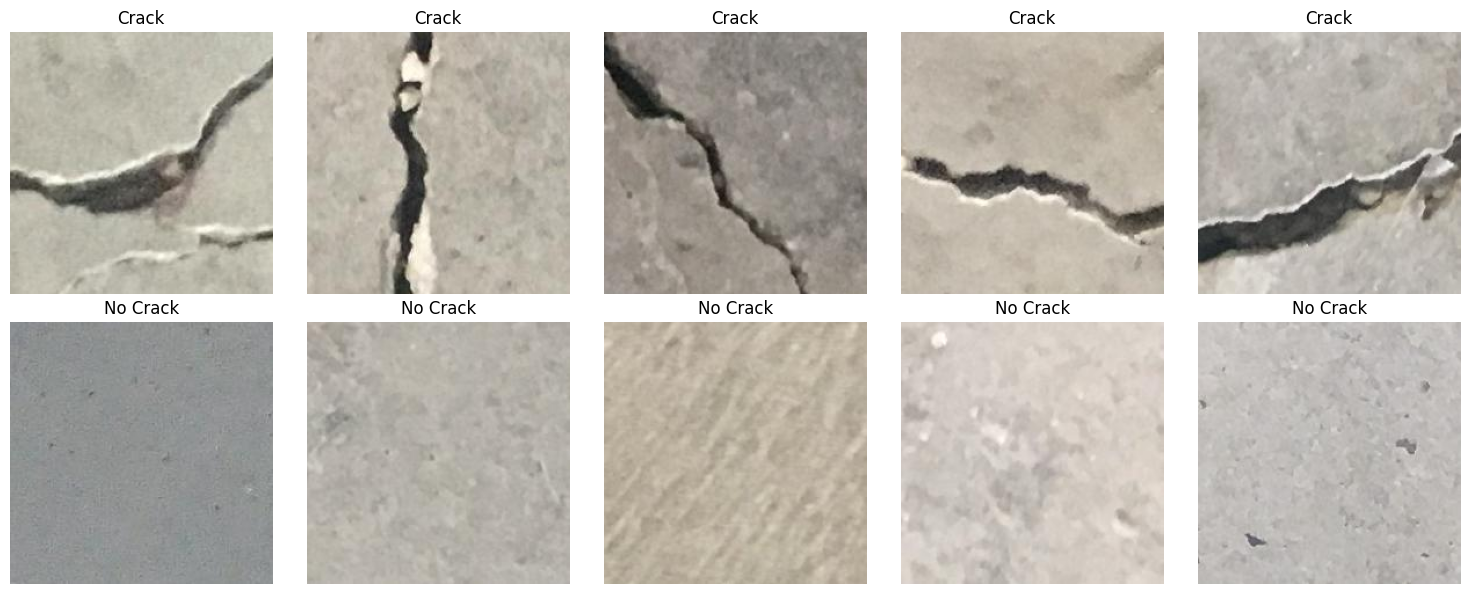

In [12]:
from PIL import Image

bad = []
for p in all_paths:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception as e:
        bad.append(p)
print("Corrupt / unreadable files:", len(bad))

keep = np.array([p not in set(bad) for p in all_paths])
all_paths, all_labels = all_paths[keep], all_labels[keep]

random.seed(42)
plt.figure(figsize=(15, 6))
for row, label in enumerate([1, 0]):
    idx = random.sample(list(np.where(all_labels == label)[0]), 5)
    for col, i in enumerate(idx):
        plt.subplot(2, 5, row * 5 + col + 1)
        plt.imshow(Image.open(all_paths[i]).convert("RGB"))
        plt.title(class_names[label])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Create train / validation / test splits (70 / 15 / 15)
**Important limitation:** the dataset has no source-photo IDs, so patches cut from the same photo can land in different splits. This random, stratified split can therefore make scores look better than they would on completely new photos.
I also drop exact duplicate files (same MD5) before splitting.

In [13]:
import hashlib
from sklearn.model_selection import train_test_split

SEED = 42

# remove exact duplicates (keep the first copy)
seen, uniq = set(), []
for i, p in enumerate(all_paths):
    h = hashlib.md5(open(p, "rb").read()).hexdigest()
    if h not in seen:
        seen.add(h); uniq.append(i)
print("Exact duplicates removed:", len(all_paths) - len(uniq))
all_paths, all_labels = all_paths[uniq], all_labels[uniq]

p_train, p_tmp, y_train, y_tmp = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name}: {len(y)} images | crack: {int(y.sum())} | no crack: {int(len(y) - y.sum())}")

# save the split so results are reproducible
save_dir = "/content/drive/MyDrive/MicroCrack_Project"
os.makedirs(save_dir, exist_ok=True)
json.dump({"seed": SEED, "train": p_train.tolist(), "val": p_val.tolist(), "test": p_test.tolist()},
          open(os.path.join(save_dir, "split_manifest.json"), "w"))
print("Split manifest saved to Drive.")

Exact duplicates removed: 1598
train: 26881 images | crack: 13779 | no crack: 13102
val: 5760 images | crack: 2952 | no crack: 2808
test: 5761 images | crack: 2953 | no crack: 2808
Split manifest saved to Drive.


## 6. Build the input pipelines
Images are resized to 224 x 224. Augmentation is applied to the **training set only**; the mild settings are chosen so hairline cracks are not erased.

In [14]:
from tensorflow.keras import layers, models

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

# mild, realistic augmentation (train only)
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.03),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.25),
])

def make_ds(paths, labels, train=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if train:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    if train:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, train=True)
val_ds   = make_ds(p_val, y_val)
test_ds  = make_ds(p_test, y_test)
print("Pipelines ready.")

Pipelines ready.


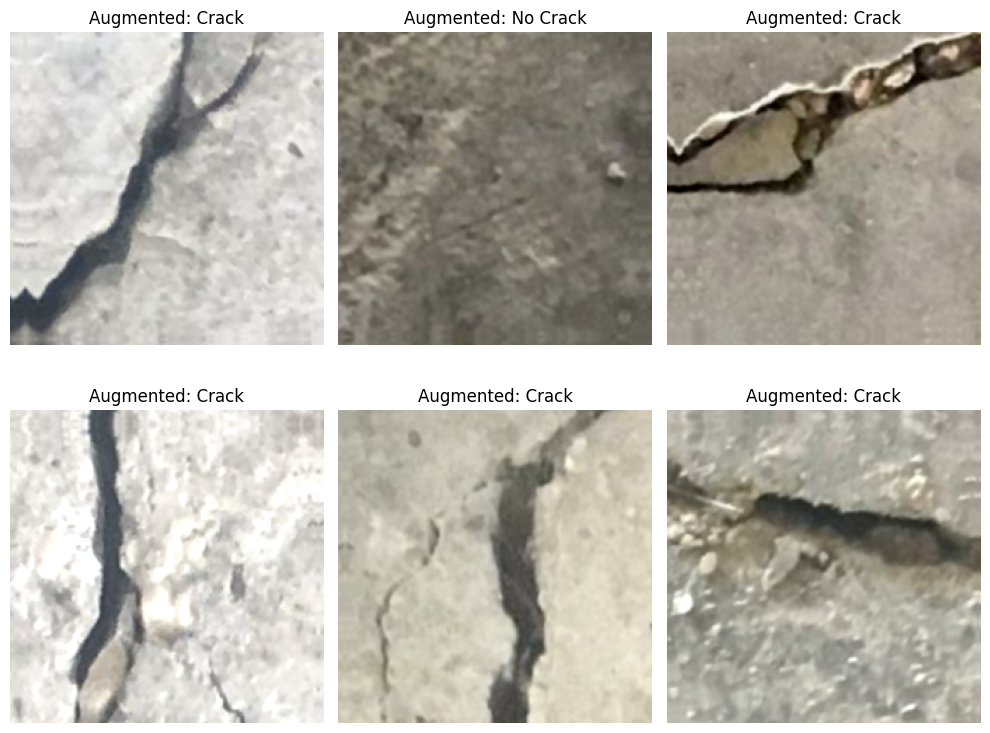

In [15]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(np.clip(images[i].numpy(), 0, 255).astype("uint8"))
        plt.title("Augmented: " + class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build the model (MobileNetV2, frozen backbone)

In [16]:
num_classes = len(class_names)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Train the classifier head
We monitor the **validation** set here. The test set is kept untouched until the final evaluation.

In [17]:
t0 = time.time()
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(train_ds, epochs=5, validation_data=val_ds, callbacks=[early_stop])
train_time_stage1 = time.time() - t0
print(f"Stage-1 training time: {train_time_stage1 / 60:.1f} min")

Epoch 1/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 306s 348ms/step - accuracy: 0.9899 - loss: 0.0269 - val_accuracy: 0.9972 - val_loss: 0.0098
Epoch 2/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 268s 319ms/step - accuracy: 0.9973 - loss: 0.0080 - val_accuracy: 0.9981 - val_loss: 0.0063
Epoch 3/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 272s 323ms/step - accuracy: 0.9976 - loss: 0.0081 - val_accuracy: 0.9977 - val_loss: 0.0070
Epoch 4/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 279s 331ms/step - accuracy: 0.9979 - loss: 0.0074 - val_accuracy: 0.9983 - val_loss: 0.0056
Epoch 5/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 317s 325ms/step - accuracy: 0.9981 - loss: 0.0064 - val_accuracy: 0.9986 - val_loss: 0.0039
Stage-1 training time: 24.0 min


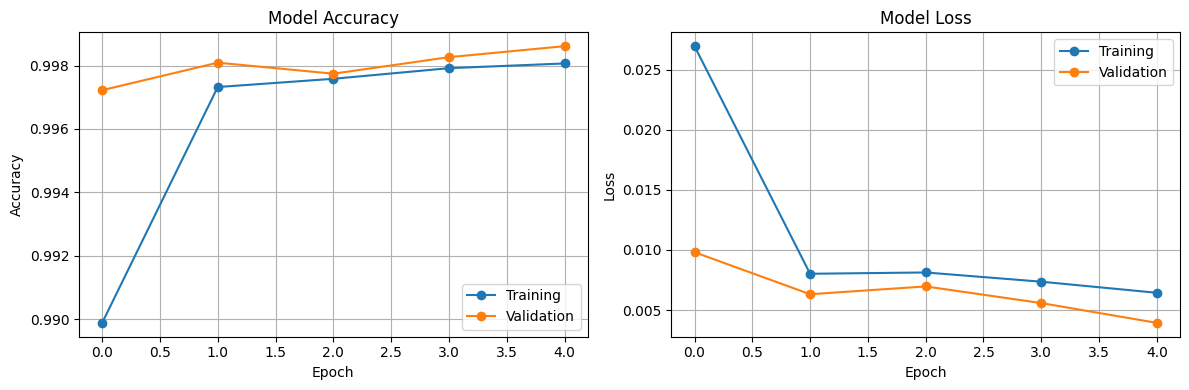

In [18]:
def plot_history(h):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(h["accuracy"], marker="o", label="Training")
    plt.plot(h["val_accuracy"], marker="o", label="Validation")
    plt.title("Model Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(True)
    plt.subplot(1, 2, 2)
    plt.plot(h["loss"], marker="o", label="Training")
    plt.plot(h["val_loss"], marker="o", label="Validation")
    plt.title("Model Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)
    plt.tight_layout(); plt.show()

plot_history(history.history)

## 9. Validation check before fine-tuning

Validation (frozen backbone) accuracy: 0.9986
Validation (frozen backbone) macro F1: 0.9986
              precision    recall  f1-score   support

    No Crack       1.00      1.00      1.00      2808
       Crack       1.00      1.00      1.00      2952

    accuracy                           1.00      5760
   macro avg       1.00      1.00      1.00      5760
weighted avg       1.00      1.00      1.00      5760



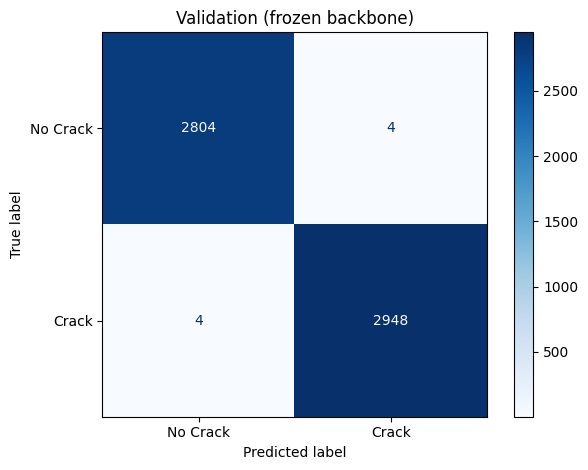

In [19]:
def evaluate(ds, y_true, title):
    y_prob = model.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    print(f"{title} accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(f"{title} macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
    print(classification_report(y_true, y_pred, labels=[0, 1], target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
    plt.title(title); plt.tight_layout(); plt.show()
    return y_prob, y_pred, cm

_ = evaluate(val_ds, y_val, "Validation (frozen backbone)")

## 10. Fine-tune the last 30 layers (very small learning rate)

In [20]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

print("Trainable parameters:", sum(tf.keras.backend.count_params(w) for w in model.trainable_weights))

Trainable parameters: 1528962


Epoch 1/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 316s 355ms/step - accuracy: 0.9930 - loss: 0.0234 - val_accuracy: 0.9972 - val_loss: 0.0081
Epoch 2/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 278s 330ms/step - accuracy: 0.9955 - loss: 0.0150 - val_accuracy: 0.9970 - val_loss: 0.0079
Epoch 3/5
841/841 ━━━━━━━━━━━━━━━━━━━━ 275s 327ms/step - accuracy: 0.9967 - loss: 0.0108 - val_accuracy: 0.9988 - val_loss: 0.0043
Fine-tuning time: 15.3 min | total training time: 39.3 min


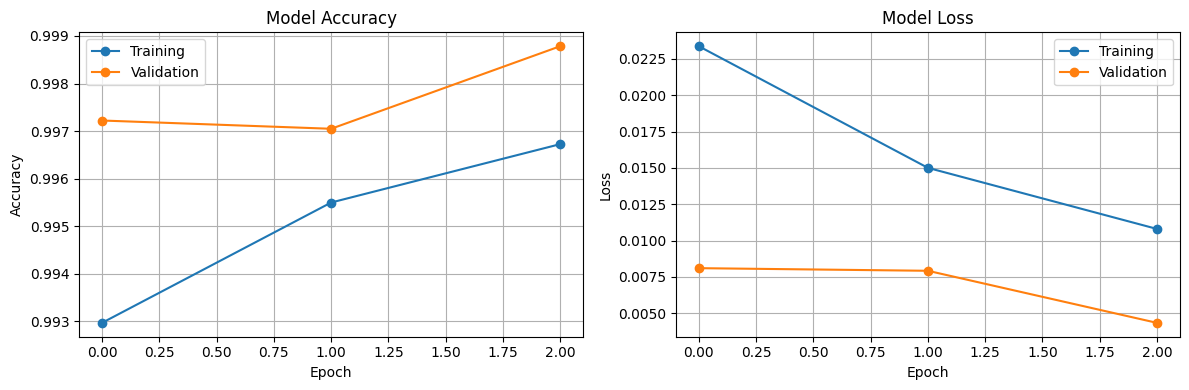

In [21]:
t0 = time.time()
history_fine = model.fit(train_ds, epochs=5, validation_data=val_ds, callbacks=[early_stop])
train_time_stage2 = time.time() - t0
total_train_min = (train_time_stage1 + train_time_stage2) / 60
print(f"Fine-tuning time: {train_time_stage2 / 60:.1f} min | total training time: {total_train_min:.1f} min")
plot_history(history_fine.history)

## 11. FINAL test-set evaluation


TEST (fine-tuned) accuracy: 0.9976
TEST (fine-tuned) macro F1: 0.9976
              precision    recall  f1-score   support

    No Crack       1.00      1.00      1.00      2808
       Crack       1.00      1.00      1.00      2953

    accuracy                           1.00      5761
   macro avg       1.00      1.00      1.00      5761
weighted avg       1.00      1.00      1.00      5761



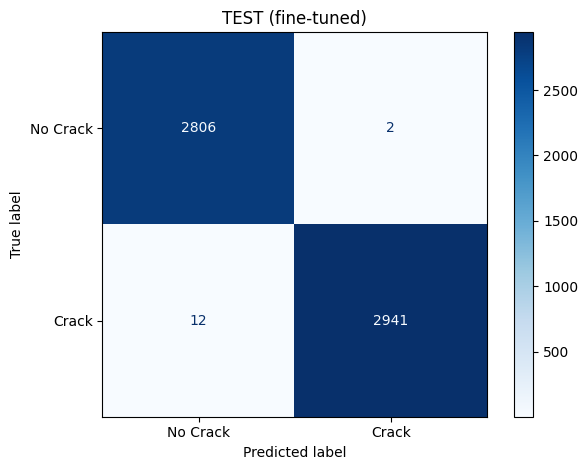

model: MobileNetV2 (fine-tuned last 30 layers)
test_n: 5761
test_accuracy: 0.9976
macro_f1: 0.9976
crack_recall: 0.9959
no_crack_recall: 0.9993
crack_precision: 0.9993
false_negatives: 12
false_positives: 2
train_time_min: 39.286
confusion_matrix: [[2806, 2], [12, 2941]]


In [22]:
y_prob, y_pred, cm = evaluate(test_ds, y_test, "TEST (fine-tuned)")

tn, fp, fn, tp = cm.ravel()
results = {
    "model": "MobileNetV2 (fine-tuned last 30 layers)",
    "test_n": int(len(y_test)),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro")),
    "crack_recall": float(tp / (tp + fn)),
    "no_crack_recall": float(tn / (tn + fp)),
    "crack_precision": float(tp / (tp + fp)) if tp + fp else None,
    "false_negatives": int(fn), "false_positives": int(fp),
    "train_time_min": float(total_train_min),
    "confusion_matrix": cm.tolist(),
}
for k, v in results.items():
    print(f"{k}: {round(v, 4) if isinstance(v, float) else v}")
json.dump(results, open(os.path.join(save_dir, "results_test.json"), "w"), indent=2)

## 12. Look at the mistakes
Missed cracks (false negatives) matter most.

Misclassified: 14 of 5761


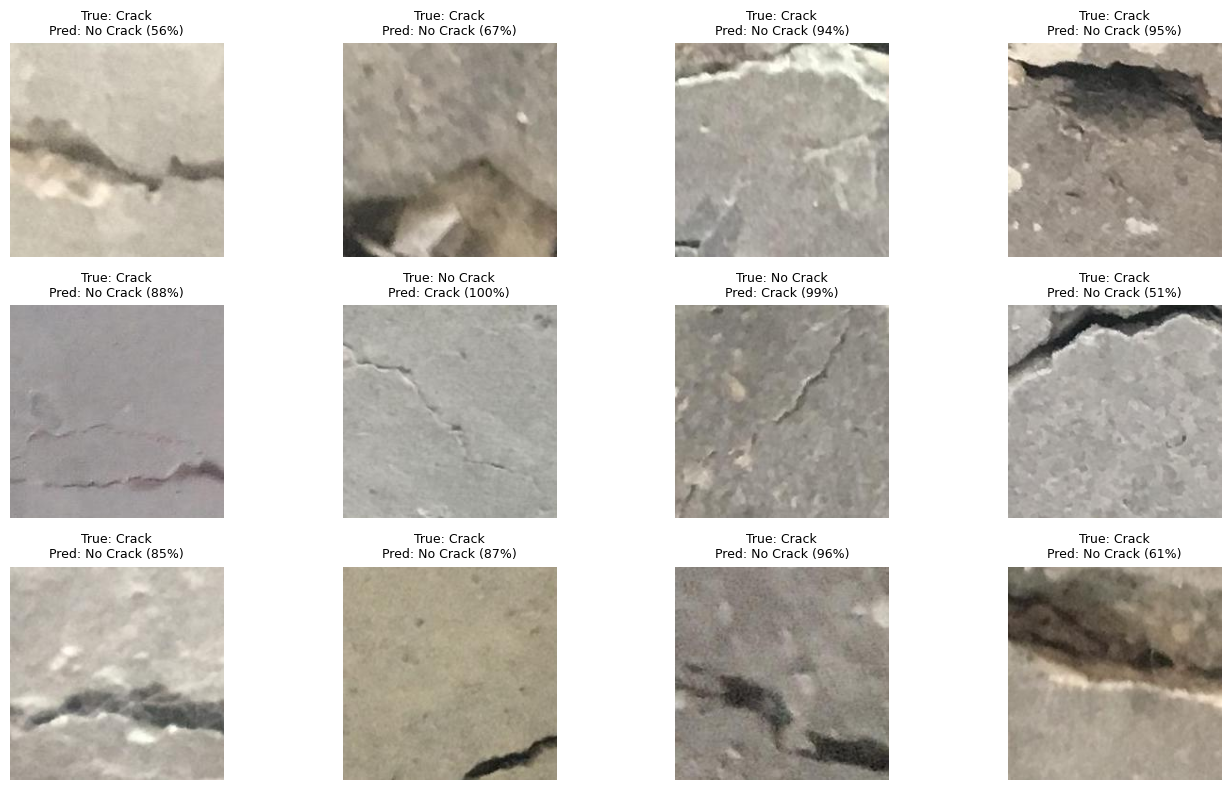

In [23]:
wrong = np.where(y_pred != y_test)[0]
print("Misclassified:", len(wrong), "of", len(y_test))
show = list(wrong[:12])
plt.figure(figsize=(14, 8))
for k, i in enumerate(show):
    plt.subplot(3, 4, k + 1)
    plt.imshow(Image.open(p_test[i]).convert("RGB"))
    plt.title(f"True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]} ({y_prob[i].max()*100:.0f}%)", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 13. Model size and CPU latency

In [24]:
os.makedirs(save_dir, exist_ok=True)
model_path = os.path.join(save_dir, "crack_model.keras")
model.save(model_path)
size_mb = os.path.getsize(model_path) / 1e6
print(f"Parameters: {model.count_params():,} | file size: {size_mb:.2f} MB")

# batch-1 CPU latency (median and 95th percentile) after warm-up
x = (np.random.rand(1, 224, 224, 3) * 255).astype("float32")
with tf.device("/CPU:0"):
    for _ in range(20):
        model(x, training=False)
    times = []
    for _ in range(100):
        t = time.perf_counter(); model(x, training=False); times.append((time.perf_counter() - t) * 1000)
print(f"CPU latency (batch 1, forward only): median {np.median(times):.2f} ms | p95 {np.percentile(times, 95):.2f} ms")
print("Note: Colab CPUs vary - always state the hardware in your report.")
results.update({"params": int(model.count_params()), "size_mb": size_mb,
                "cpu_ms_median": float(np.median(times)), "cpu_ms_p95": float(np.percentile(times, 95))})
json.dump(results, open(os.path.join(save_dir, "results_test.json"), "w"), indent=2)

Parameters: 2,260,546 | file size: 21.89 MB
CPU latency (batch 1, forward only): median 246.66 ms | p95 279.27 ms
Note: Colab CPUs vary - always state the hardware in your report.


## 14. Compression: TensorFlow Lite (dynamic-range INT8 weights)
Compare size AND accuracy - compression is only useful if recall on cracks survives.

In [25]:
export_dir = "/content/crack_savedmodel"
model.export(export_dir)

converter = tf.lite.TFLiteConverter.from_saved_model(export_dir)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
tflite_path = os.path.join(save_dir, "crack_model_dynamic.tflite")
open(tflite_path, "wb").write(tflite_model)
print(f"TFLite size: {len(tflite_model) / 1e6:.2f} MB (Keras: {size_mb:.2f} MB)")

interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

tfl_pred = []
for xb, _ in test_ds:
    for img in xb.numpy():
        interp.set_tensor(inp["index"], img[None].astype(np.float32))
        interp.invoke()
        tfl_pred.append(int(np.argmax(interp.get_tensor(out["index"])[0])))
tfl_pred = np.array(tfl_pred)
print("TFLite test accuracy:", round(accuracy_score(y_test, tfl_pred), 4))
print("TFLite macro F1:", round(f1_score(y_test, tfl_pred, average="macro"), 4))
print(classification_report(y_test, tfl_pred, labels=[0, 1], target_names=class_names, zero_division=0))

Saved artifact at '/content/crack_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_160')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132083470054224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470054416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470052304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470056144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470054608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470053840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470050384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470051728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470050192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132083470052112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite test accuracy: 0.9976
TFLite macro F1: 0.9976
              precision    recall  f1-score   support

    No Crack       1.00      1.00      1.00      2808
       Crack       1.00      1.00      1.00      2953

    accuracy                           1.00      5761
   macro avg       1.00      1.00      1.00      5761
weighted avg       1.00      1.00      1.00      5761



## 15. Predict on your own image

Saving 00002.jpg to 00002.jpg


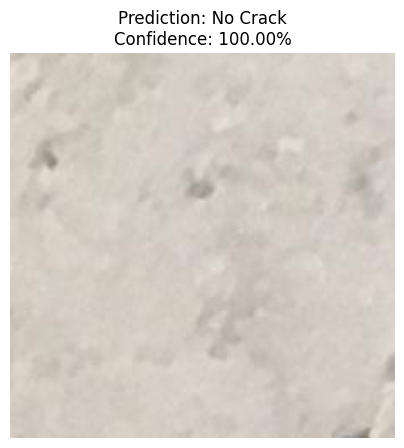

Predicted class: No Crack
Confidence: 100.00%
Screening aid only - not a structural-safety assessment.


In [26]:
from google.colab import files

uploaded_image = files.upload()
image_name = next(iter(uploaded_image))

img = Image.open(image_name).convert("RGB")
image_array = np.expand_dims(np.array(img.resize((224, 224)), dtype=np.float32), axis=0)

predictions = model.predict(image_array, verbose=0)[0]
predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

plt.figure(figsize=(5, 5))
plt.imshow(img); plt.axis("off")
plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
if confidence < 80:
    print("⚠️ Low confidence - send this image for human inspection.")
print("Screening aid only - not a structural-safety assessment.")

## 16. Save class names

In [27]:
class_names_path = os.path.join(save_dir, "class_names.json")
with open(class_names_path, "w") as f:
    json.dump(class_names, f, indent=4)
print("Class names saved:", class_names)

Class names saved: ['No Crack', 'Crack']
